In [1]:
# Run this cell to completely clear GPU and System RAM
if 'dataset' in locals():
    del dataset
if 'dataloader' in locals():
    del dataloader
if 'model' in locals():
    del model

import torch
import gc

torch.cuda.empty_cache() # Clear VRAM
gc.collect()             # Clear System RAM

20

In [3]:
import os
import gc
import pandas as pd
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from torchvision import transforms
from PIL import Image
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor

# --- 0. RAM/VRAM Cleanup ---
# Deletes old variables if they exist to prevent OOM errors on re-runs
if 'dataset' in locals(): del dataset
if 'dataloader' in locals(): del dataloader
torch.cuda.empty_cache()
gc.collect()

class RiboflavinFastMemoryDataset(Dataset):
    def __init__(self, csv_file, data_root, transform=None, device='cuda'):
        self.device = device
        self.transform = transform
        
        # 1. Load CSV and consolidate memory
        print("Reading CSV...")
        self.data = pd.read_csv(csv_file).copy()
        
        # 2. Recursive Path Mapping (os.walk)
        # This ignores your folder naming issues and finds images by filename
        path_map = {}
        print(f"Scanning {data_root} for images...")
        for root, _, files in os.walk(data_root):
            for file in files:
                if file.endswith(".bmp"):
                    path_map[file] = os.path.join(root, file)
        
        # 3. Filter CSV for existing files
        self.data['exists'] = self.data.iloc[:, 0].map(lambda x: x in path_map)
        self.data = self.data[self.data['exists']].reset_index(drop=True)
        print(f"Found {len(self.data)} valid image-parameter pairs.")

        # --- 4. Brute-Force Feature Cleaning ---
        print("Cleaning and Scaling features...")
        
        # Select all numeric columns
        df_global = self.data.iloc[:, 2:21]
        df_grid = self.data.iloc[:, 21:149]

        def clean_dataframe(df):
            # A. Convert everything to numeric, forcing errors to NaN
            df = df.apply(pd.to_numeric, errors='coerce')
            
            # B. Fill any actual NaNs with the column mean (or 0 if mean is NaN)
            df = df.fillna(df.mean()).fillna(0)
            
            # C. Replace positive/negative infinity with 0
            df = df.replace([np.inf, -np.inf], 0)
            
            # D. Drop columns where every value is the same (zero variance)
            df = df.loc[:, df.nunique() > 1]
            return df

        df_global = clean_dataframe(df_global)
        df_grid = clean_dataframe(df_grid)
        
        print(f"Kept {len(df_global.columns)} global and {len(df_grid.columns)} grid features.")

        # Save sizes for model initialization
        self.num_global_params = len(df_global.columns)
        self.num_grid_params = len(df_grid.columns)

        # Scale with a small epsilon to prevent division by zero
        scaler = StandardScaler()
        g_feat = scaler.fit_transform(df_global.values)
        s_feat = scaler.fit_transform(df_grid.values)
        
        self.global_features = torch.tensor(g_feat, dtype=torch.float32).to(self.device)
        self.grid_features = torch.tensor(s_feat, dtype=torch.float32).to(self.device)

        # FINAL GPU-SIDE CHECK
        if torch.isnan(self.global_features).any():
            print("ERROR: Global features still contain NaNs after scaling!")
            # Last resort: Force all NaNs to 0
            self.global_features = torch.nan_to_num(self.global_features, 0.0)

        # 5. Parallel Multi-threaded Image Loading
        print(f"Loading images into {self.device} RAM (8 threads)...")
        
        def load_and_prep(idx):
            img_name = self.data.iloc[idx, 0]
            with Image.open(path_map[img_name]) as img:
                img_gray = img.convert('L')
                if self.transform:
                    return self.transform(img_gray)
                return transforms.ToTensor()(img_gray)

        with ThreadPoolExecutor(max_workers=8) as executor:
            # list(tqdm(...)) ensures we see a progress bar for the load
            img_list = list(tqdm(executor.map(load_and_prep, range(len(self.data))), 
                                 total=len(self.data), desc="Progress"))
            
        # Stack into one massive tensor on GPU: [Batch, 1, 64, 64]
        self.images = torch.stack(img_list).to(self.device)
        
        # Final cleanup of temporary CPU objects
        del img_list
        gc.collect()
        print("Dataset successfully moved to GPU.")

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        # Returns directly from GPU memory
        return self.global_features[idx], self.grid_features[idx], self.images[idx]

# --- Initialization Execution ---

# 1. Setup transformations (matching CNN training specs)
train_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

# 2. Identify Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 3. Create Dataset and Loader
# Point 'Data/' to your parent directory containing all date/concentration folders
dataset = RiboflavinFastMemoryDataset(
    csv_file='riboflavin_features.csv', 
    data_root='Data/', 
    transform=train_transform,
    device=device
)

# Batch size can be high since everything is already on VRAM
dataloader = DataLoader(dataset, batch_size=64, shuffle=True)

print(f"\nSUCCESS: Data ready for {device}. Batch count: {len(dataloader)}")

Reading CSV...
Scanning Data/ for images...
Found 4413 valid image-parameter pairs.
Cleaning and Scaling features...
Kept 19 global and 128 grid features.
Loading images into cuda RAM (8 threads)...


Progress: 100%|██████████████████████████████████████| 4413/4413 [04:26<00:00, 16.58it/s]


Dataset successfully moved to GPU.

SUCCESS: Data ready for cuda. Batch count: 69


In [4]:
import torch.nn as nn

class CrystalReconstructor(nn.Module):
    def __init__(self, global_in, grid_in):
        super(CrystalReconstructor, self).__init__()

        self.global_mlp = nn.Sequential(
            nn.Linear(global_in, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2),
            nn.Linear(1024, 2048),
            nn.LeakyReLU(0.2),
            # ← no extra Linear(2048, 2048) here
        )

        grid_channels = grid_in // 64
        self.grid_conv = nn.Sequential(
            nn.Conv2d(grid_channels, 64, kernel_size=3, padding=1),  # 64, not 32
            nn.BatchNorm2d(64),
            nn.ReLU()
        )

        self.decoder = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
            nn.Conv2d(96, 128, kernel_size=3, padding=1),  # 32+64=96
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
            nn.Conv2d(128, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True),
            nn.Conv2d(64, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, 1, kernel_size=3, padding=1),
            nn.Sigmoid()
        )

    def forward(self, g, s):
        g = self.global_mlp(g).view(-1, 32, 8, 8)  # 2048 = 32*8*8

        channels = s.shape[1] // 64
        s = s.view(-1, channels, 8, 8)
        s = self.grid_conv(s)                        # → (batch, 64, 8, 8)

        combined = torch.cat((g, s), dim=1)          # → (batch, 96, 8, 8)
        return self.decoder(combined)

# Initialize the model with the dataset's actual counts
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CrystalReconstructor(dataset.num_global_params, dataset.num_grid_params).to(device)

In [5]:
import os
import torch.optim as optim
from tqdm import tqdm

weights_dir = "MLP-Weights"
os.makedirs(weights_dir, exist_ok=True)

total_epochs = 500

# model was already moved to device: model.to(device)
criterion = nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=50, gamma=0.5)

for epoch in range(total_epochs):
    model.train()
    total_loss = 0
    
    # tqdm makes a nice progress bar
    loop = tqdm(dataloader, desc=f"Epoch {epoch+1}/{total_epochs}", leave=False)
    
    for g, s, img in loop:
        # DATA IS ALREADY ON GPU - no .to(device) needed!
        
        output = model(g, s)
        loss = criterion(output, img)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        loop.set_postfix(loss=loss.item())

    scheduler.step()

    # if (epoch + 1) % 250 == 0:
    #     save_path = os.path.join(weights_dir, f"model_epoch_{epoch+1}.pth")
    #     torch.save({
    #         'epoch': epoch + 1,
    #         'model_state_dict': model.state_dict(),
    #         'optimizer_state_dict': optimizer.state_dict(),
    #         'loss': total_loss/len(dataloader),
    #     }, save_path)
    #     print(f"\n---> Saved checkpoint: {save_path}")
    
    if (epoch + 1) % 10 == 0:
        print(f"Final Epoch {epoch+1} Avg Loss: {total_loss/len(dataloader):.5f}")

Final Epoch 10 Avg Loss: 0.05174


Final Epoch 20 Avg Loss: 0.05020


Final Epoch 30 Avg Loss: 0.04889


Final Epoch 40 Avg Loss: 0.04843


Final Epoch 50 Avg Loss: 0.04793


Final Epoch 60 Avg Loss: 0.04661


... (40 outputs left out)

Final Epoch 470 Avg Loss: 0.04122


Final Epoch 480 Avg Loss: 0.04120


Final Epoch 490 Avg Loss: 0.04123


Final Epoch 500 Avg Loss: 0.04122


In [ ]:
import torch
import os

# 2. Define the path to your saved file
weights_dir = "MLP-Weights"
load_path = os.path.join(weights_dir, "empty.pth")

if os.path.exists(load_path):
    # 3. Load the dictionary (map to current device)
    checkpoint = torch.load(load_path, map_location=device)
    
    # 4. Load the weights into the model
    model.load_state_dict(checkpoint['model_state_dict'])
    
    # 5. Optional: Load the optimizer state if you are continuing training
    # optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    
    # 6. Optional: Retrieve other saved info
    start_epoch = checkpoint['epoch']
    saved_loss = checkpoint['loss']
    
    print(f"Successfully loaded checkpoint from epoch {start_epoch}")
    print(f"Loss at time of saving: {saved_loss:.5f}")
else:
    print("Checkpoint file not found.")

# IMPORTANT: Set to eval mode if you are only doing testing/prediction
model.eval()

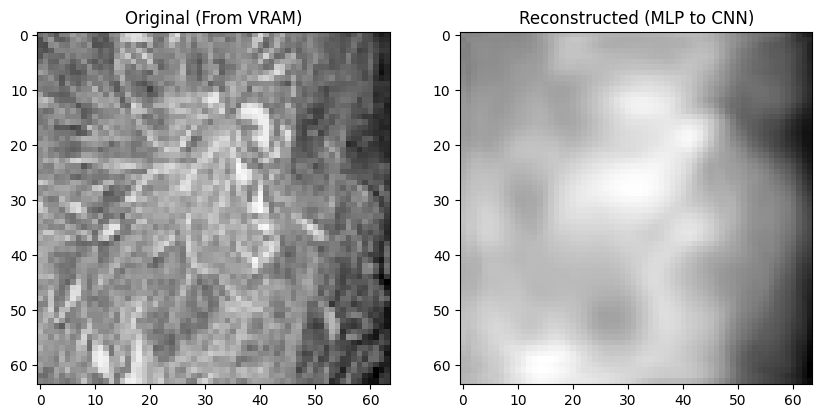

In [6]:
import matplotlib.pyplot as plt

model.eval()
with torch.no_grad():
    # Grab one batch from the GPU-resident loader
    g, s, img = next(iter(dataloader))
    
    # Generate reconstruction
    pred = model(g, s).cpu() # Move only the result back to CPU for plotting
    
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(img[0].cpu().squeeze(), cmap='gray')
    axes[0].set_title("Original (From VRAM)")
    
    axes[1].imshow(pred[0].squeeze(), cmap='gray')
    axes[1].set_title("Reconstructed (MLP to CNN)")
    plt.show()

Starting overfit test on 1 image...
Iteration 0, Loss: 0.096626
Iteration 100, Loss: 0.015815
Iteration 200, Loss: 0.011260
Iteration 300, Loss: 0.008626
Iteration 400, Loss: 0.007185
Iteration 500, Loss: 0.006347


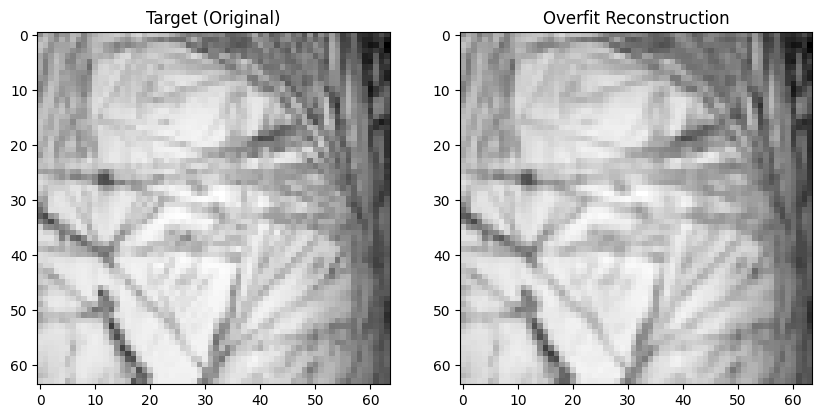

In [7]:
import matplotlib.pyplot as plt

# 1. Setup the model and a fresh optimizer
model = CrystalReconstructor(dataset.num_global_params, dataset.num_grid_params).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.0005)
criterion = torch.nn.L1Loss() # Sharper than MSE for crystals

# 2. Grab a SINGLE data point (the first one)
g, s, img = dataset[0]
# Add batch dimension [1, features]
g = g.unsqueeze(0).to(device)
s = s.unsqueeze(0).to(device)
img = img.unsqueeze(0).to(device)

print("Starting overfit test on 1 image...")
model.train()

# 3. Training Loop
for i in range(501):
    output = model(g, s)
    loss = criterion(output, img)
    
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    if i % 100 == 0:
        print(f"Iteration {i}, Loss: {loss.item():.6f}")

# 4. Display Results
model.eval()
with torch.no_grad():
    pred = model(g, s).cpu()

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(img.cpu().squeeze(), cmap='gray')
axes[0].set_title("Target (Original)")
axes[1].imshow(pred.squeeze(), cmap='gray')
axes[1].set_title("Overfit Reconstruction")
plt.show()